# 05 · The dry season (Season C)

From June to August most of Rwanda gets little rain (notebook 04), and most land lies idle. A farmer with an
irrigation kit can grow a **whole extra crop** then. The yield bonus in Seasons A and B (notebook 03) misses this,
so here we measure:

1. **What a watered Season C hectare harvests**, in RWF at survey farm-gate prices.
2. **How much watered land is farmed in Season C**, compared with watered land in Seasons A and B.

Values are harvest value **before seed, fertilizer and labour**: a whole crop carries costs that the A/B yield
bonus (same inputs, more harvest) does not.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from kuhira import district_stats as ds
from kuhira import season_c as sc
from kuhira import style
from kuhira.paths import INTERIM

style.use()
ab = pd.read_parquet(INTERIM / "plots.parquet")
c = pd.read_parquet(INTERIM / "plots_C.parquet")
prices = ds.crop_prices(ds.recent_small(ab))
values = sc.plot_values(c, prices)
f"{len(values):,} small-farm Season C plots with a harvest, {int((values.irrigated == 1).sum()):,} of them watered"

'16,793 small-farm Season C plots with a harvest, 9,648 of them watered'

## What watered dry-season land grows
Mostly vegetables and Irish potato: high-value crops that need water.

In [2]:
mix = sc.irrigated_crop_mix(c)
(mix * 100).round(1).head(8).rename("% of watered Season C area").to_frame()

,% of watered Season C area
group,
Vegetables,52.1
Irish potato,23.2
Sweet potato,7.9
Beans,7.5
Pea,4.5
Soybean,3.4
Fruits,1.3
Other crops,0.1


## What a watered dry-season hectare is worth
Each plot's crops valued at median farm-gate prices (SAS 2023–25), divided by the plot's area; the extreme 1% at
each end dropped. Watered plots are compared with the unwatered dry-season plots (mostly valley bottoms with
leftover moisture), which are *not* the right comparison for a kit on hillside land that would otherwise lie idle.

'Watered Season C hectare, all years: RWF 1,567,388 (median)'

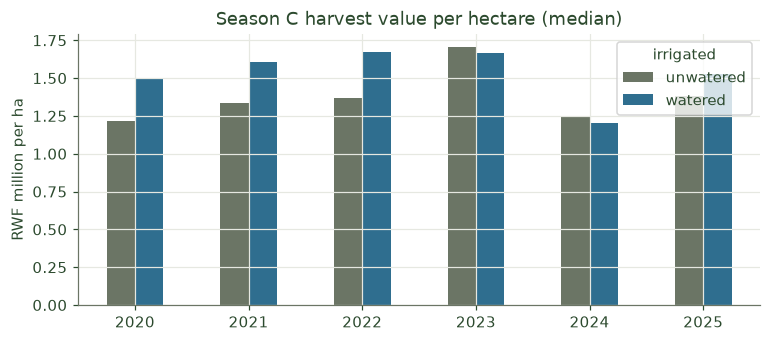

In [3]:
by_year = values.groupby(["year", "irrigated"]).rwf_per_ha.median().unstack().rename(
    columns={0.0: "unwatered", 1.0: "watered"})
ax = (by_year / 1e6).plot(kind="bar", color=[style.MUTED, style.WATER], figsize=(8, 3.2))
ax.set(ylabel="RWF million per ha", xlabel="", title="Season C harvest value per hectare (median)")
plt.xticks(rotation=0)
value = sc.irrigated_value_per_ha(values)
f"Watered Season C hectare, all years: RWF {value:,.0f} (median)"

Stable across years (about RWF 1.2–1.7 M), far above the A/B yield bonus (about RWF 30–50 thousand per hectare
per season). The dry season is where irrigation's money is.

## How much watered land is farmed in the dry season
The survey cannot follow one farmer from one season's sample to the next (IDs are listed afresh each season), so we
compare **land**: survey-weighted watered Season C hectares against the average watered hectares in Seasons A and B.

year
2020      5.0
2021     34.0
2022     42.0
2023    101.0
2024     83.0
2025     44.0
dtype: float64

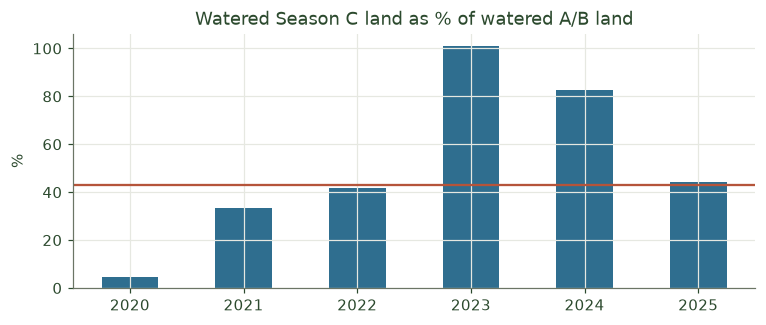

In [4]:
uptake = sc.uptake_by_year(ab, c)
ax = (uptake * 100).plot(kind="bar", color=style.WATER, figsize=(8, 3))
ax.axhline(uptake.median() * 100, color=style.CLAY, lw=1.5)
ax.set(ylabel="%", xlabel="", title="Watered Season C land as % of watered A/B land")
plt.xticks(rotation=0)
(uptake * 100).round(0)

It swings a lot from year to year (the dry-season sample changes), so we use the **median, about 43%**, as the
default and let planners change it. Read it as: for every 100 hectares of new kits, about 43 also carry a
dry-season crop.

## What this adds and what it does not
- It adds a separate "dry-season harvest" line to the plan and to the farmer calculator.
- It does **not** change the ranking: the value is one national figure (district samples are too thin), so it
  lifts every district equally.
- It is gross harvest value; seed, fertilizer and labour are not subtracted.